# Heart Disease Prediction with Machine Learning (Python, scikit-learn)
**Practice notebook — Rishabh Aryan.** Written after the IIT Ropar guest lectures in the IIT Ropar & NIELIT Ropar 6-Month AI/ML programme.

Goal: predict the presence of heart disease from 13 clinical attributes of the **UCI Heart Disease (Cleveland)** dataset, compare several classifiers with stratified cross-validation, and interpret the best model.

Dataset: Janosi, Steinbrunn, Pfisterer & Detrano (1989), *Heart Disease*, UCI Machine Learning Repository, doi:10.24432/C52P4X, CC BY 4.0.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.inspection import permutation_importance
SEED = 42
sns.set_theme(style="whitegrid")
DATA = Path("../data")

## 1. Load the data
The raw file has no header and uses `?` for missing values. Column names follow the UCI documentation.

In [2]:
cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
raw = pd.read_csv(DATA/"processed.cleveland.data", header=None, names=cols, na_values="?")
raw.shape

(303, 14)

In [3]:
raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Clean and define the target
`num` ranges from 0 (no disease) to 4. As is standard for this dataset, we predict presence (1-4) vs absence (0).

In [4]:
df = raw.copy()
df["target"] = (df.pop("num") > 0).astype(int)
print("missing values per column:"); print(df.isna().sum()[lambda s: s > 0])
print("duplicate rows:", df.duplicated().sum())
df["target"].value_counts().rename({0:"no disease",1:"disease"})

missing values per column:
ca      4
thal    2
dtype: int64
duplicate rows: 0


target
no disease    164
disease       139
Name: count, dtype: int64

## 3. Exploratory data analysis

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


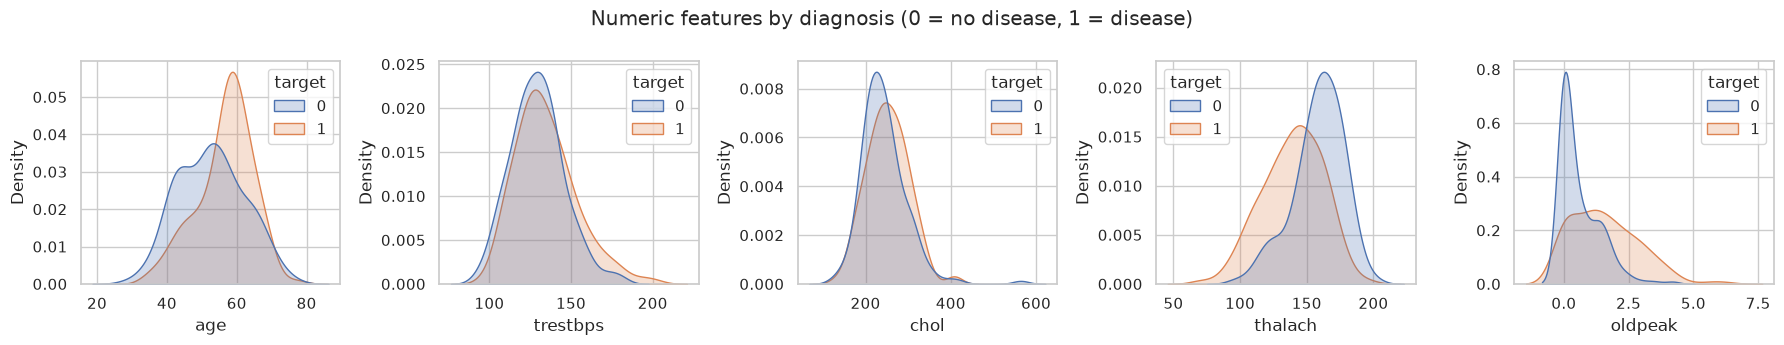

In [6]:
num_cols = ["age","trestbps","chol","thalach","oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue="target", fill=True, common_norm=False, ax=ax)
fig.suptitle("Numeric features by diagnosis (0 = no disease, 1 = disease)"); plt.tight_layout(); plt.show()

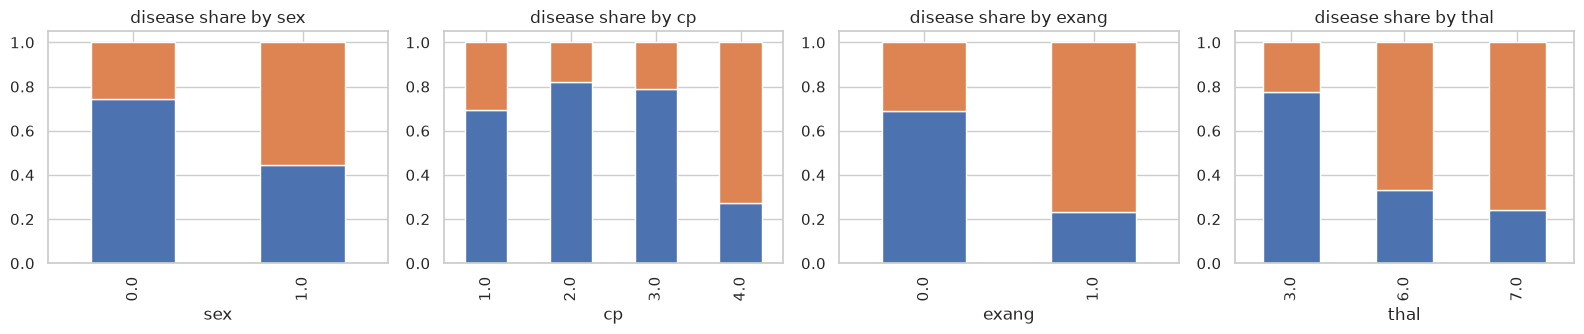

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, ["sex","cp","exang","thal"]):
    pd.crosstab(df[c], df["target"], normalize="index").plot.bar(stacked=True, ax=ax, legend=False)
    ax.set_title(f"disease share by {c}")
plt.tight_layout(); plt.show()

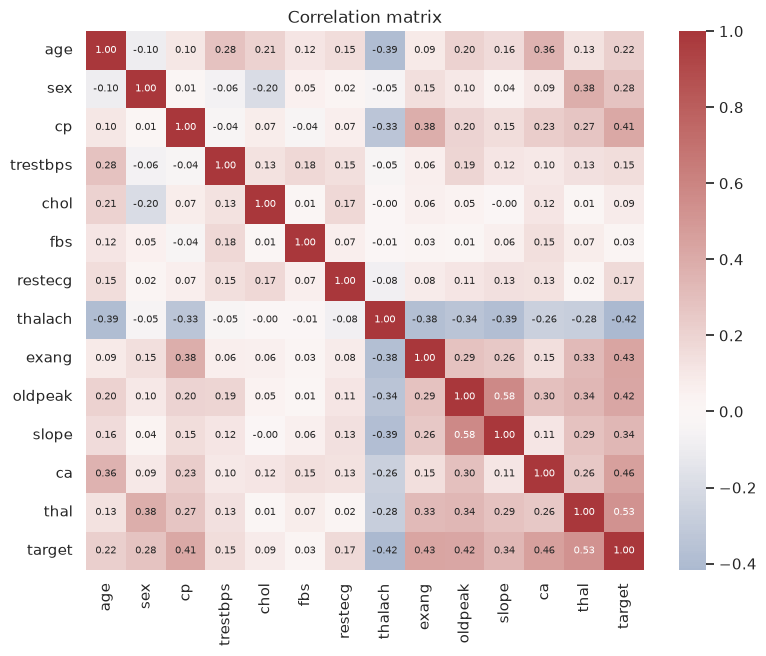

In [8]:
plt.figure(figsize=(9,7))
sns.heatmap(df.corr(), cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size":7})
plt.title("Correlation matrix"); plt.show()

## 4. Preprocessing pipeline
Numeric features: median imputation + scaling. Categorical features: most-frequent imputation + one-hot encoding. Everything sits inside a `Pipeline`, so it is fitted only on training folds (no leakage).

In [9]:
num_feats = ["age","trestbps","chol","thalach","oldpeak","ca"]
cat_feats = ["sex","cp","fbs","restecg","exang","slope","thal"]
X, y = df[num_feats + cat_feats], df["target"]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_feats),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_feats),
])
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "K-nearest neighbours": KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)": SVC(probability=True, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=400, random_state=SEED),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
}

## 5. Model comparison — 10-fold stratified cross-validation

In [10]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(Pipeline([("prep", prep), ("clf", m)]), X, y, cv=cv,
                       scoring=["accuracy","f1","roc_auc"])
    rows.append({"model": name,
                 "accuracy": r["test_accuracy"].mean(), "accuracy_sd": r["test_accuracy"].std(),
                 "f1": r["test_f1"].mean(), "roc_auc": r["test_roc_auc"].mean()})
cv_table = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
cv_table

/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be r

/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/workspace/ml1/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,accuracy,accuracy_sd,f1,roc_auc
model,,,,
Logistic regression,0.845,0.054,0.823,0.912
SVM (RBF),0.838,0.048,0.814,0.906
Random forest,0.815,0.054,0.791,0.905
K-nearest neighbours,0.815,0.055,0.788,0.901
Gradient boosting,0.815,0.047,0.792,0.891
Majority baseline,0.541,0.011,0.000,0.500


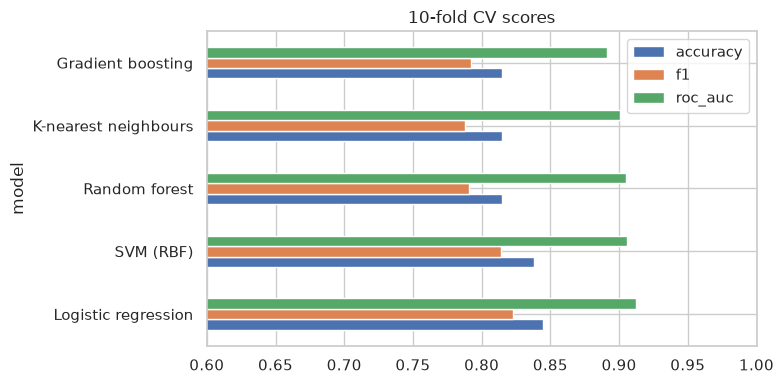

In [11]:
ax = cv_table.drop(index="Majority baseline")[["accuracy","f1","roc_auc"]].plot.barh(figsize=(8,4))
ax.set_xlim(0.6, 1); ax.set_title("10-fold CV scores"); plt.tight_layout(); plt.show()

## 6. Hold-out evaluation of logistic regression
A stratified 80/20 split, used once, to show a confusion matrix and ROC curve.

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
best = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))]).fit(X_tr, y_tr)
pred = best.predict(X_te)
print(classification_report(y_te, pred, target_names=["no disease","disease"], digits=3))
print("hold-out ROC-AUC:", round(roc_auc_score(y_te, best.predict_proba(X_te)[:,1]), 3))

              precision    recall  f1-score   support

  no disease      0.931     0.818     0.871        33
     disease      0.812     0.929     0.867        28

    accuracy                          0.869        61
   macro avg      0.872     0.873     0.869        61
weighted avg      0.877     0.869     0.869        61

hold-out ROC-AUC: 0.958


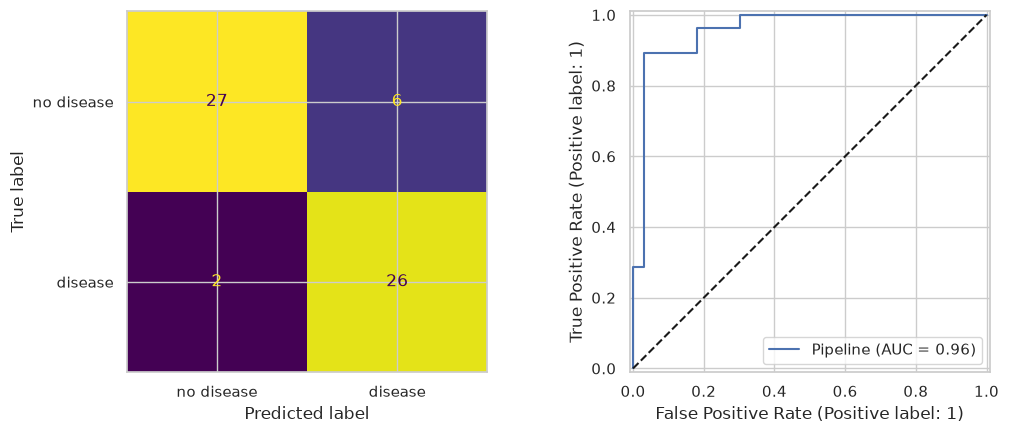

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["no disease","disease"], ax=axes[0], colorbar=False)
RocCurveDisplay.from_estimator(best, X_te, y_te, ax=axes[1]); axes[1].plot([0,1],[0,1],"k--")
plt.tight_layout(); plt.show()

## 7. Interpretation — permutation importance (hold-out set)

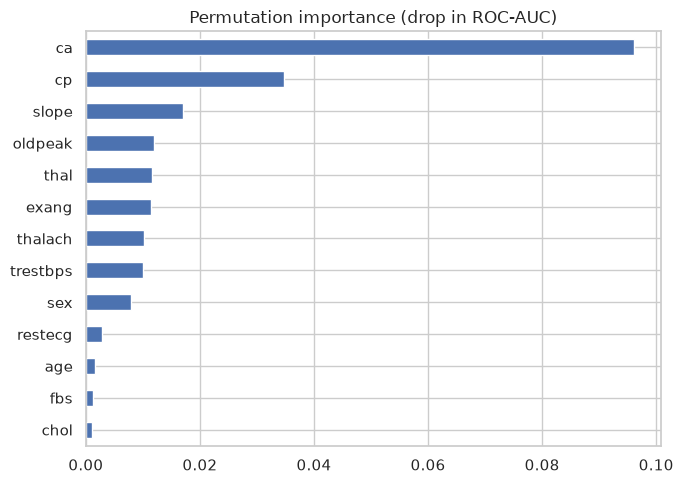

ca         0.096
cp         0.035
slope      0.017
oldpeak    0.012
thal       0.012
exang      0.011
dtype: float64

In [14]:
imp = permutation_importance(best, X_te, y_te, n_repeats=30, random_state=SEED, scoring="roc_auc")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importance.plot.barh(figsize=(7,5), title="Permutation importance (drop in ROC-AUC)"); plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(3).head(6)

## 8. Takeaways
* All real models beat the majority baseline by a wide margin; differences between the better models are small relative to their fold-to-fold spread (see `accuracy_sd`), so a simple, interpretable logistic regression is a reasonable choice.
* Permutation importance highlights which clinical attributes drive the predictions on this split.
* Limitations: 303 patients from one hospital (Cleveland), so results may not transfer to other populations; this is a learning exercise, **not** a medical tool.